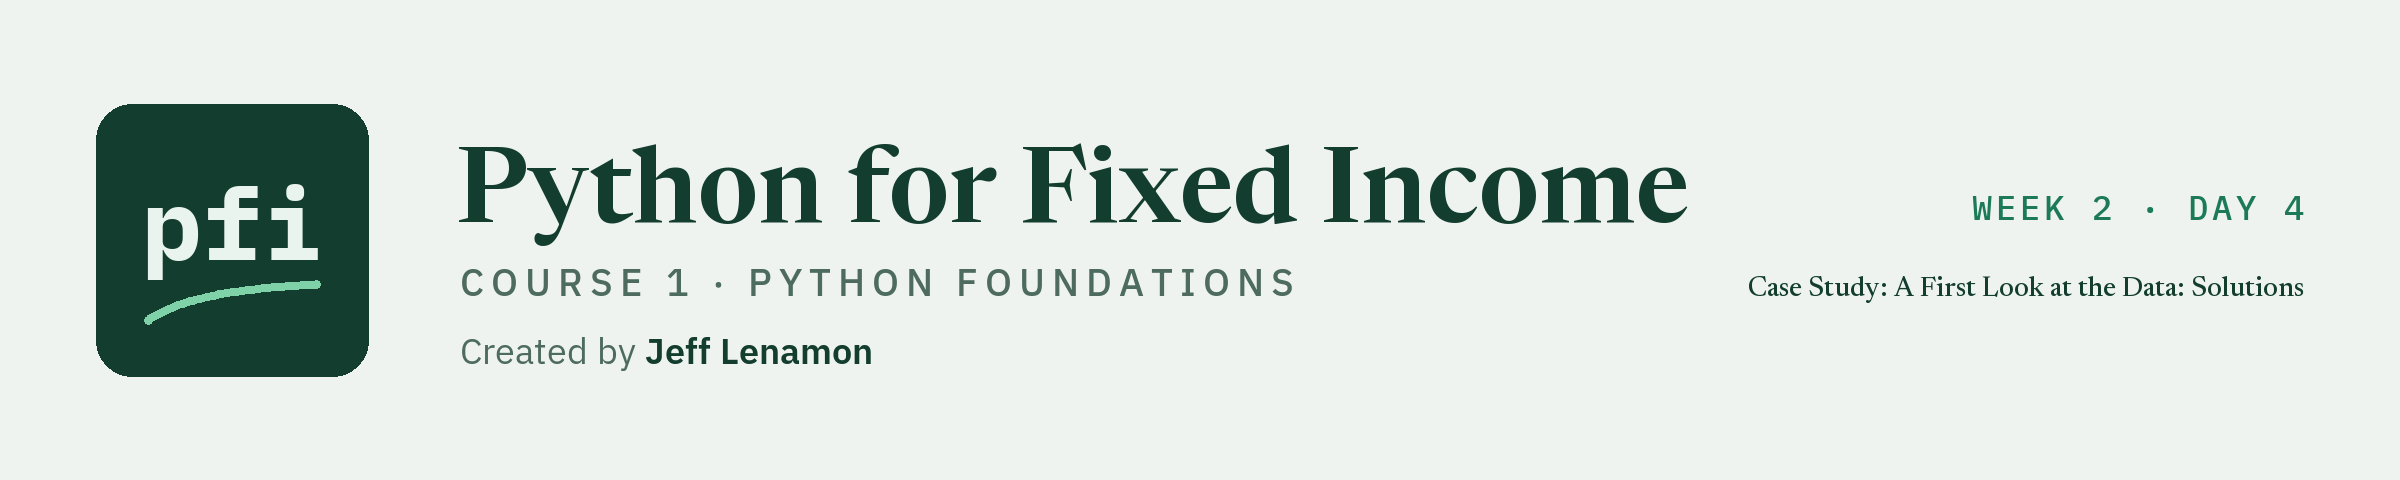

# Case Study: A First Look at the Data: Solutions

Week 2, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day4/09_case_study_first_look_at_the_data_solutions.ipynb)

## Exercises

These are the worked answers to the exercises in the teaching notebook, on `benchmark.csv`, one row per benchmark bond; the issuers are invented.
Each answer is followed by the check cell from the teaching notebook.
Run the next two cells first: the first defines `check`; the second loads the benchmark and fresh copies of the three tables.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import pandas as pd

# the benchmark, and fresh copies of the three tables. In Colab they are read from GitHub.
if os.path.exists('../../../data/benchmark.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

benchmark = pd.read_csv(data_folder + 'benchmark.csv')
positions = pd.read_csv(data_folder + 'positions.csv')
issuers = pd.read_csv(data_folder + 'issuers.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(len(benchmark), len(positions), len(issuers), len(ratings))

821 200 150 18


### Exercise 1

Q. Store the benchmark's shape in **ex1_shape**, and the number of its text columns, counted by eye from the types, in **ex1_text_columns**.

In [3]:
ex1_shape = benchmark.shape
print(ex1_shape)

# the type of every column
print(benchmark.dtypes)

# counted from the list above: as_of_date, cusip, ticker, issuer, sector, rating,
# maturity, price_date
ex1_text_columns = 8

(821, 19)
as_of_date                str
cusip                     str
ticker                    str
issuer                    str
sector                    str
rating                    str
coupon                float64
maturity                  str
price                 float64
price_date                str
accrued               float64
yield_pct             float64
oas                     int64
duration              float64
spread_duration       float64
dts                   float64
amount_outstanding      int64
market_value          float64
weight_pct            float64
dtype: object


821 rows and 19 columns.
Eight columns are text, and three of those are dates stored as text: `as_of_date`, `maturity`, and `price_date`.

In [4]:
check('Exercise 1 shape', ex1_shape, (821, 19))
check('Exercise 1 text columns', ex1_text_columns, 8)

Exercise 1 shape: correct
Exercise 1 text columns: correct


### Exercise 2

Q. How many values are missing in the whole benchmark? How many rows copy an earlier row? Is the CUSIP unique? Store the answers in **ex2_missing**, **ex2_duplicates**, and **ex2_cusip_unique**.

In [5]:
# missing values per column, then added into one number
ex2_missing = benchmark.isna().sum().sum()

# rows that repeat an earlier row
ex2_duplicates = benchmark.duplicated().sum()

# True when no CUSIP appears twice
ex2_cusip_unique = benchmark['cusip'].is_unique

print('Missing values:', ex2_missing)
print('Duplicate rows:', ex2_duplicates)
print('CUSIP unique:', ex2_cusip_unique)

Missing values: 0
Duplicate rows: 0
CUSIP unique: True


Nothing is missing, no row is repeated, and each of the 821 CUSIPs appears once.
One row of the benchmark is one bond, identified by its CUSIP.

In [6]:
check('Exercise 2 missing', ex2_missing, 0)
check('Exercise 2 duplicates', ex2_duplicates, 0)
check('Exercise 2 CUSIP unique', ex2_cusip_unique, True)

Exercise 2 missing: correct
Exercise 2 duplicates: correct
Exercise 2 CUSIP unique: correct


### Exercise 3

Q. How many distinct tickers does the benchmark have, what is the most bonds any one ticker has, and is every benchmark ticker in the issuers table? Store the answers in **ex3_tickers**, **ex3_most_bonds**, and **ex3_all_found**.

In [7]:
ex3_tickers = benchmark['ticker'].nunique()

# value_counts() gives the bonds under each ticker, and max() the largest of those counts
ex3_most_bonds = benchmark['ticker'].value_counts().max()

# one True or False per benchmark bond, then all() asks whether every one is True
ex3_all_found = benchmark['ticker'].isin(issuers['ticker']).all()

print('Distinct tickers:', ex3_tickers)
print('Most bonds for one ticker:', ex3_most_bonds)
print('Every ticker found in issuers:', ex3_all_found)

Distinct tickers: 150
Most bonds for one ticker: 8
Every ticker found in issuers: True


150 distinct tickers across 821 bonds, with at most 8 bonds for one ticker.
The benchmark has 150 tickers and the issuers table 150 rows, so the benchmark covers every issuer in the reference data.

In [8]:
check('Exercise 3 tickers', ex3_tickers, 150)
check('Exercise 3 most bonds', ex3_most_bonds, 8)
check('Exercise 3 all found', ex3_all_found, True)

Exercise 3 tickers: correct
Exercise 3 most bonds: correct
Exercise 3 all found: correct


### Exercise 4

Q. With `isin()` on the CUSIP, and no merge: is every position in the benchmark, and how many benchmark bonds does the desk hold, and not hold? Store the answers in **ex4_all_found**, **ex4_held**, and **ex4_not_held**.

In [9]:
# every position, tested against the benchmark's CUSIPs
ex4_all_found = positions['cusip'].isin(benchmark['cusip']).all()

# every benchmark bond, tested against the desk's CUSIPs
held = benchmark['cusip'].isin(positions['cusip'])
ex4_held = held.sum()
ex4_not_held = (~held).sum()

print('Every position found in the benchmark:', ex4_all_found)
print('Benchmark bonds held:', ex4_held)
print('Benchmark bonds not held:', ex4_not_held)

Every position found in the benchmark: True
Benchmark bonds held: 200
Benchmark bonds not held: 621


Every one of the desk's 200 CUSIPs is a benchmark bond; the desk holds 200 of the 821 and does not hold 621.
Combining Part 1's merge gave the same two counts; `isin()` gets them without building a joined table.

In [10]:
check('Exercise 4 all found', ex4_all_found, True)
check('Exercise 4 held', ex4_held, 200)
check('Exercise 4 not held', ex4_not_held, 621)

Exercise 4 all found: correct
Exercise 4 held: correct
Exercise 4 not held: correct


### Exercise 5

Q. Write `count_not_found(table, lookup, key)`, returning how many rows of `table` have a `key` value missing from that column of `lookup`; replace `return ...` with your code. Use it to count the issuers with no bond, in **ex5_issuers_not_held**, then write one `assert`, with a message, that every position's ticker is in the issuers table.

In [11]:
def count_not_found(table, lookup, key):
    """
    Take two tables and the name of a column they share,
    and return the number of rows of the first table
    whose value in that column is not found in the second table.
    """
    # True for each row of the table whose key is in the lookup
    found = table[key].isin(lookup[key])
    # ~ swaps True and False, and the sum of a mask is a count
    return (~found).sum()


# issuers with no bond in the positions
ex5_issuers_not_held = count_not_found(issuers, positions, 'ticker')
print(f'Issuers with no position: {ex5_issuers_not_held:,}')

# the same function on the CUSIP: benchmark bonds the desk does not hold
print(f"Benchmark bonds not held: {count_not_found(benchmark, positions, 'cusip'):,}")

# a check that stops the notebook if a position ever arrives without an issuer
assert count_not_found(positions, issuers, 'ticker') == 0, 'a ticker is missing from issuers'

Issuers with no position: 35
Benchmark bonds not held: 621


35 issuers have no position, the lesson's Predict 4 count, and the same function on the CUSIP gives Exercise 4's 621.
The `assert` prints nothing, because every position's ticker is found; on a file where one is missing, it stops the notebook with the message.
The function takes the name of the key as text, so one definition covers the ticker, the CUSIP, and the rating.

In [12]:
# the first check calls your function on the benchmark and the positions
check('Exercise 5 benchmark not held', count_not_found(benchmark, positions, 'cusip'), 621)
check('Exercise 5 issuers not held', ex5_issuers_not_held, 35)

Exercise 5 benchmark not held: correct
Exercise 5 issuers not held: correct


### Exercise 6

Q. Flag the benchmark bonds priced below 100 (`below_par`), with an OAS above 300 (`wide`), and a duration above 10 (`long`). How many carry all three flags, and how many none? Store the answers in **ex6_all_three** and **ex6_none**.

In [13]:
# one True or False column for each test
flags = pd.DataFrame({
    'below_par': benchmark['price'] < 100,
    'wide': benchmark['oas'] > 300,
    'long': benchmark['duration'] > 10,
})

# add across each row: how many flags each bond carries
flag_count = flags.sum(axis=1)

ex6_all_three = (flag_count == 3).sum()
ex6_none = (flag_count == 0).sum()
print(flags.sum())
print('Bonds with all three flags:', ex6_all_three)
print('Bonds with no flag:', ex6_none)

below_par    449
wide         120
long          96
dtype: int64
Bonds with all three flags: 4
Bonds with no flag: 275


4 benchmark bonds carry all three flags and 275 carry none.
The single flags catch 449, 120, and 96 bonds, so most of the benchmark is caught by one test or none.
A mask on `flags.sum(axis=1)`, one count per bond, is the same step as a mask on a column.

In [14]:
check('Exercise 6 all three', ex6_all_three, 4)
check('Exercise 6 none', ex6_none, 275)

Exercise 6 all three: correct
Exercise 6 none: correct


### Exercise 7: AI check

An AI assistant wrote the code below to count the benchmark bonds the desk does not hold.
It was written for this course in the style of an AI answer, and it has one bug.

Q. What number do you expect, from Exercise 4? Run the code. Does it agree?

The answer from Exercise 4 is 621; the original code printed 159, with no error.
The bug was the column: it tested the benchmark's `ticker` against the desk's tickers, so it marked a bond as held whenever the desk holds any bond of the same issuer.
A bond is identified by its CUSIP, and the ticker repeats: 150 tickers cover the 821 benchmark bonds.
159 is a real count of something else, the benchmark bonds of the 35 issuers the desk does not hold at all.
The lesson's first key test catches it: before matching two tables on a column, ask whether that column identifies one row.

In [15]:
# True for each benchmark bond whose CUSIP is in the desk's positions
held = benchmark['cusip'].isin(positions['cusip'])

# the bonds not held are the ones where held is False
ex7_not_held = (~held).sum()

print(f'Benchmark bonds the desk does not hold: {ex7_not_held}')

Benchmark bonds the desk does not hold: 621


In [16]:
check('Exercise 7 not held', ex7_not_held, 621)

Exercise 7 not held: correct
